# 3.3 — Fairness / disparate impact (deferred from Fase 2)

**Goal**: `regiao` was excluded as a feature on fairness grounds (2.1) — proxy for protected
attributes, redlining risk. This is the deferred check: does `policy_v1` leave **residual
disparate impact by region**, via the correlation between `regiao` and the policy's inputs?

**Input**: `data/processed/applications_segmented.parquet` + `references/policy_v1.yaml` (3.2).

**Scope caveats**: `regiao` is known only where a snapshot exists (~52% of the funnel — the
`(missing)` segment carries no region), so the test covers the region-known population;
"proposed approval" is the simulated rule outcome (same transfer hypothesis as 3.2 §4).
`classe_social`/`status_empregaticio` are *deliberate* policy inputs — the axis under test here
is region only. Metric: the **four-fifths rule** (min/max approval ratio ≥ 0.80).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR / "src"))
from credit_policy import policy as pol  # noqa: E402  (path set above)

sns.set_theme(style="whitegrid")

app = pd.read_parquet(PROJECT_DIR / "data" / "processed" / "applications_segmented.parquet")
policy = pol.load_policy(PROJECT_DIR / "references" / "policy_v1.yaml")

reg = app[app["regiao"].notna()].copy()
reg["proposed"] = pol.approve(reg, policy)
reg["current"] = reg["STATUS"].isin(["Contratado", "Aprovado"])

t = reg.groupby("regiao").agg(n=("uuid", "size"), current=("current", "mean"),
                              proposed=("proposed", "mean"))
t["book_default"] = reg[reg["OVER30M2"].notna()].groupby("regiao")["OVER30M2"].mean()
t = t.sort_values("book_default")

di_cur, di_prop = t["current"].min() / t["current"].max(), t["proposed"].min() / t["proposed"].max()
print(f"regiao coverage: {app['regiao'].notna().mean():.1%} of the funnel")
print(f"four-fifths (min/max approval): current {di_cur:.3f} -> proposed {di_prop:.3f} "
      f"(threshold 0.80)")
t.style.format({"current": "{:.1%}", "proposed": "{:.1%}", "book_default": "{:.1%}", "n": "{:,}"})

regiao coverage: 51.9% of the funnel
four-fifths (min/max approval): current 0.832 -> proposed 0.931 (threshold 0.80)


,n,current,proposed,book_default
regiao,,,,
Sul,"7,645",46.9%,77.6%,6.2%
Centro-Oeste,"9,003",49.7%,77.8%,8.5%
Norte,"7,678",50.9%,73.3%,8.7%
Sudeste,"68,348",45.7%,75.6%,9.1%
Nordeste,"21,813",42.3%,72.4%,11.2%


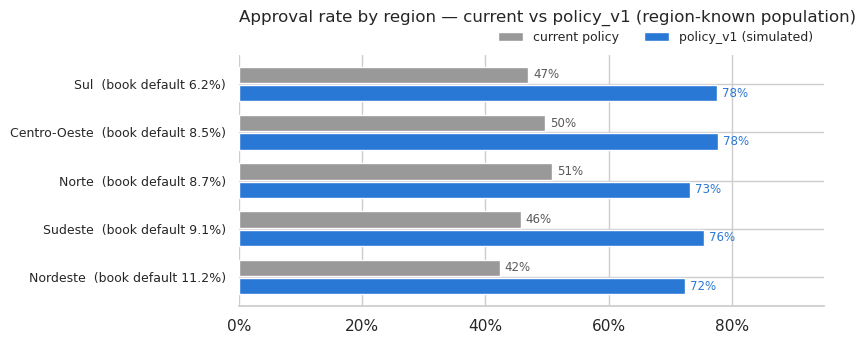

In [2]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ypos = np.arange(len(t))
ax.barh(ypos - 0.19, t["current"], height=0.34, color="0.6", label="current policy")
ax.barh(ypos + 0.19, t["proposed"], height=0.34, color="#2a78d6", label="policy_v1 (simulated)")
for i, (c, p) in enumerate(zip(t["current"], t["proposed"])):
    ax.text(c + 0.008, i - 0.19, f"{c:.0%}", va="center", fontsize=8.5, color="0.35")
    ax.text(p + 0.008, i + 0.19, f"{p:.0%}", va="center", fontsize=8.5, color="#2a78d6")
ax.set_yticks(ypos, [f"{r}  (book default {d:.1%})" for r, d in t["book_default"].items()],
              fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 0.95)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Approval rate by region — current vs policy_v1 (region-known population)",
             loc="left", pad=24)
ax.legend(ncols=2, loc="lower right", bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=9)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Key takeaway — no residual disparate impact; disparity narrows.** Both policies pass the
four-fifths rule, but `policy_v1` **improves** the ratio: 0.832 → 0.931. Under the current
policy the largest gap is Nordeste (42.3% approval) vs Norte (50.9%); under `policy_v1` the
spread compresses to 72.1–77.5%, and residual differences track the *measured* book risk
(Nordeste is also the riskiest region at 11.2% vs Sul 6.2%) rather than region itself —
consistent with a policy whose only inputs are the deliberate segment dims and the score.

## Key takeaways

- **Four-fifths passes with margin** and improves vs the current policy (0.832 → 0.931):
  excluding `regiao` as a feature did not leave residual regional disparate impact; it removed
  some of the existing one.
- **Caveats**: test limited to the region-known ~52% of the funnel; proposed approvals are
  simulated under the 3.2 transfer hypothesis. Re-run on realized approvals once the policy (or
  its staged test) goes live, and extend to other protected axes if data becomes available.
- **Fase 3 complete**: segmentation (3.0) → validated baseline & score axis + missing rule (3.1)
  → frontier & operating point `policy_v1.yaml` (3.2) → fairness check (3.3).